Please fill in your name and your student number.


In [ ]:
from itertools import combinations

Name = "Seyed Kiarash Eshraghi"
Student_Number = "403101383"


### Libraries

In [5]:
# Run the following code to import the necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import lu

# Problem 1 

## 1‑1 Gaussian Elimination

### Part 1:
- In many engineering and applied mathematics problems, Gaussian elimination is used to systematically simplify a system of linear equations.

- By applying elementary row operations, the algorithm converts a matrix into an upper triangular structure, making further computations such as back‑substitution straightforward.

- Instead of directly solving the system, the focus of this problem is on the matrix transformation process itself.

---

## During the elimination process:

- A pivot element is selected in each column.
- Rows may be exchanged to ensure the pivot is non‑zero and numerically reliable.
- Multiples of the pivot row are subtracted from the rows below to eliminate lower‑column entries.
- The elimination continues until all elements below each pivot are zero.

---

## Task

 Create a Python function named gaussian_elimination(A) that performs Gaussian elimination on a square matrix.

### Your function should:

 - Output a tuple containing(transformed upper triangular matrix, total row exchanges)
 - Use only basic Python constructs (lists, loops, arithmetic).
 - Not rely on any external or built‑in matrix libraries.
### Example

**Input:**

$$
\begin{bmatrix}
1 & -2 & 1 \\
3 & 1 & -4 \\
2 & -3 & -1
\end{bmatrix}
$$

**Output:**

$$
\begin{bmatrix}
3 & 1 & -4 \\
 0 & -2.33 & 2.33 \\
 0 & 0 & -5
\end{bmatrix}
$$

In [8]:
def finding_Partial_Pivoting(matrix, i):
    m=abs(matrix[i][i])
    k=i
    n=len(matrix)
    for j in range(i + 1, n):
        if abs(matrix[j][i])>m:
            m=abs(matrix[j][i])
            k=j
    if k==i:
        return matrix, False
    matrix[i], matrix[k] = matrix[k], matrix[i]
    return matrix, True

def gaussian_elimination(matrix):
    matrix = [list(row) for row in matrix]

    c=0
    n=len(matrix)
    for i in range(n):
        matrix, swapped = finding_Partial_Pivoting(matrix, i)
        if swapped:
            c+=1
        pivot = matrix[i][i]
        if pivot==0:
            continue
        for k in range(i + 1, n):
            a = matrix[k][i]/pivot
            for j in range(i,n):
                matrix[k][j]-=a*matrix[i][j]

    return matrix, c


In [16]:
# Evaluation Cell
# Do not change anything here except what is allowed
myprint = True  # If an error happens, print the failing test case
np.random.seed(42)
all_passed = True  # Flag to track success
for i in range(500):
    n = np.random.randint(2, 10)
    A = np.random.randint(-10, 10, size=(n, n))
    pl, expected_A_ref = lu(A, permute_l=True)
    result_ref = gaussian_elimination(A.astype(float))[0]
    if not np.allclose(result_ref, expected_A_ref):
        all_passed = False
        if myprint:
            print(f"❌ Test Case {i + 1} Failed:")
            print("Matrix A:")
            print(A)
            print("\nUser Output:")
            print(result_ref)
            print("\nExpected Output:")
            print(expected_A_ref)
        break  # Stop at the first failing test
if all_passed:
    print("✅ All test cases passed!")


✅ All test cases passed!


# 1‑2 Gauss–Jordan Elimination
 Gauss–Jordan elimination is an extension of the standard Gaussian elimination technique.

 Instead of stopping at an upper‑triangular echelon form, the method proceeds further by eliminating all entries above each pivot and by scaling  pivots to 1, ultimately converting the matrix into its **Reduced Row Echelon Form (RREF)**.

#### RREF is particularly useful in linear algebra because it allows us to:

 - Solve systems of linear equations directly,
 - Determine the inverse of a matrix when it exists,
 - Compute the rank of a matrix.
## In this process:

 1. We move from left to right searching for pivot positions,
 2. Use row operations to create zeros below each pivot (forward elimination),
 3. Normalize the pivot so that it becomes exactly 1,
 4. And then eliminate all non‑zero entries above the pivot (backward elimination).
 The final result is a matrix where each pivot column has a single “1” and all other entries in that column are zero.

---
### Row operation matrix

A `Row Operation Matrix (P)` is a rectangle matrix that represents the cumulative effect of all row operations applied to a matrix, such that multiplying it by the original matrix produces the transformed RREF matrix.

$$
    P \cdot A = RREF
$$

 **P** is noy unique most of the times but it is surely invertible.

---


### Programming Task

Write a Python function `gauss_jordan_elimination(matrix)` that performs **Gauss-Jordan elimination** on a given matrix and transform it into its **reduced row echelon form (RREF)**.

### 2. Returns a tuple `(RREF, P)` representing the matrix’s **reduced row echelon form (RREF)** and **Row operation matrix (p)** .


### Requirements
 - The input matrix is given as a list of lists.
 - You may not use any built‑in matrix operations or external numerical libraries.
 - All row operations must be implemented manually.

---

### Example: 4×5 Matrix, its RREF, and the Row Operation Matrix $P$

Original matrix \(A\):

$$
A =
\begin{bmatrix}
1 & 2 & -1 & 0 & 3 \\
2 & 4 & -2 & 1 & 7 \\
0 & 1 &  1 & 2 & 1 \\
1 & 0 &  3 & 1 & 4
\end{bmatrix}
$$

RREF(A):

$$RREF=
\begin{bmatrix}
1 & 0 & 0 & 0 & 1 \\
0 & 1 & 0 & 0 & -1 \\
0 & 0 & 1 & 0 & 2 \\
0 & 0 & 0 & 1 & -1
\end{bmatrix}
$$

Row Operation Matrix \(P\) :

$$
P =
\begin{bmatrix}
1 & -2 & 1 & 0 \\
0 &  1 & -1 & 0 \\
0 &  0 &  1 & -1 \\
-1 & 2 & -1 & 1
\end{bmatrix}
$$


In [13]:
def making_P(n):
    P = [[1 if i == j else 0 for j in range(n)] for i in range(n)]
    return P

def finding_Partial_Pivoting(matrix, i, P):
    matrix = [list(row) for row in matrix]
    m = abs(matrix[i][i])
    k = i
    n = len(matrix)
    for j in range(i + 1, n):
        if abs(matrix[j][i]) > m:
            m = abs(matrix[j][i])
            k = j
    if k == i:
        return matrix, False, P
    matrix[i], matrix[k] = matrix[k], matrix[i]
    P[i], P[k] = P[k], P[i]
    return matrix, True, P

def gauss_jordan_elimination(matrix):
    matrix = [list(row) for row in matrix]
    num_rows = len(matrix)
    num_cols = len(matrix[0])
    P = making_P(num_rows)
    for i in range(min(num_rows, num_cols)):
        matrix, swapped, P = finding_Partial_Pivoting(matrix, i, P)

        pivot = matrix[i][i]
        if abs(pivot) < 1e-12:
            continue
        for j in range(num_cols):
            matrix[i][j] /= pivot
        for j in range(num_rows):
            P[i][j] /= pivot

        for k in range(num_rows):
            if k != i:
                factor = matrix[k][i]
                for j in range(num_cols):
                    matrix[k][j] -= factor * matrix[i][j]
                for j in range(num_rows):
                    P[k][j] -= factor * P[i][j]

    return matrix,P


In [11]:
# Evaluation Cell
A = np.array([
    [1, 2, 1, 3],
    [2, 4, 3, 7],
    [-1, -2, 0, -1]
], dtype=float)

A_expected = np.array([
    [1, 2, 0, 0],
    [0, 0, 1, 0],
    [0, 0, 0, 1]
], dtype=float)

B = np.array([
    [2, 1, -1, 3],
    [4, 2, 1, 1],
    [-2, -1, 2, 4]
], dtype=float)

B_expected = np.array([
    [1, 0.5, 0, 0],
    [0, 0, 1, 0],
    [0, 0, 0, 1]
], dtype=float)




C = np.array([
    [1, 2, 1, 3, 4],
    [2, 4, 3, 5, 8],
    [-1, -2, 2, 0, 0],
    [3, 6, 4, 8, 12]
], dtype=float)

C_expected = np.array([
    [1, 2, 0, 0, 4/3],
    [0, 0, 1, 0, 2/3],
    [0, 0, 0, 1, 2/3],
    [0, 0, 0, 0, 0]
], dtype=float)


tests = [
    ("A", A, A_expected),
    ("B", B, B_expected),
    ("C", C, C_expected)
]

all_passed = True

for name, matrix, correct in tests:
    result, _ = gauss_jordan_elimination(matrix)

    if not np.allclose(result, correct):
        all_passed = False
        print(f"❌ Test Case {name} Failed:")
        print(f"Matrix {name}:")
        print("\nUser Output:")
        print(np.array(result))
        print("\nExpected Output:")
        print(np.array(correct))
        print("\n" + "-"*50 + "\n")

if all_passed:
    print("✅ All test cases passed!")

ValueError: too many values to unpack (expected 2, got 3)

## 1-3 Inverse of a Matrix
The inverse of a matrix $A$, denoted as $A^{-1}$, is a matrix that satisfies:

$$
A A^{-1} = A^{-1} A = I
$$

where $I$ is the **identity matrix**.

A matrix $ A $ has an inverse if and only if:
- It is a **square matrix**.
- It is **non-singular**, meaning its **determinant is not zero**.
- Its **rows and columns are linearly independent**.

If a matrix does not satisfy these conditions, it is called a **singular matrix**, and its inverse does **not exist**.

---

For a **2×2 matrix**:

$$
A = \begin{bmatrix} a & b \\ c & d \end{bmatrix}
$$

The inverse is:

$$
A^{-1} = \frac{1}{\det(A)} \begin{bmatrix} d & -b \\ -c & a \end{bmatrix}
$$

where the **determinant** is:

$$
\det(A) = ad - bc
$$

#### Using Gauss-Jordan Elimination (for larger matrices):
For $ 3 \times 3 $ or higher matrices, we use **row operations** to transform $ A $ into the identity matrix.

**Steps:**
1. Augment $ A $ with the identity matrix $[A | I]$.
2. Perform **row operations** to convert $ A $ into $ I $.
3. The transformed right-hand side becomes $ A^{-1} $.

---

Write a Python function `inverse_matrix(matrix)` that takes a matrix as input and return it's inverse.

- You are **not allowed** to use any library functions for matrix operations. You must implement the method from scratch. Feel free to use the functions you have implemented previously.
- You can use `np.linalg.inv` to test your function.

In [22]:
def making_P(n):
    return [[1.0 if i==j else 0.0 for j in range(n)] for i in range(n)]
def finding_Partial_Pivoting(matrix, i, P):
    m=abs(matrix[i][i])
    k=i
    n=len(matrix)
    for j in range(i + 1, n):
        if abs(matrix[j][i])>m:
            m=abs(matrix[j][i])
            k=j
    if k!=i:
        matrix[i], matrix[k]=matrix[k], matrix[i]
        P[i], P[k]=P[k],P[i]
    return matrix,P

def inverse_matrix(matrix):
    matrix = [list(row) for row in matrix]
    n=len(matrix)
    P=making_P(n)
    for i in range(n):
        matrix, P=finding_Partial_Pivoting(matrix, i, P)
        pivot=matrix[i][i]
        if pivot==0:
            raise ValueError("Singular Matrix")
        for j in range(n):
            matrix[i][j]/=pivot
            P[i][j]/=pivot
        for k in range(n):
            if k!=i:
                factor=matrix[k][i]
                for j in range(n):
                    matrix[k][j]-=factor*matrix[i][j]
                    P[k][j]-=factor*P[i][j]

    return P


In [23]:
def generate_invertible_matrix(n):
    while True:
        A = np.random.randn(n, n)  
        if abs(np.linalg.det(A)) > 1e-5:  
            return A
n = np.random.randint(3, 10)  
A = generate_invertible_matrix(n)
A_inv=inverse_matrix(A.copy())
I_approx=A @ A_inv
I_exact=np.eye(n)
assert np.linalg.norm(I_approx - I_exact) < 1e-10, "A * A_inv ≠ I, inverse computation is incorrect"

print("status: successful")

status: successful


## 1-4 Row‑Equivalent Matrices 

Two matrices are called row‑equivalent if one can be obtained from the other through a finite sequence of elementary row operations. In other words, they represent the same row‑space even if their entries look different.

Every matrix is row‑equivalent to its own RREF, and the RREF of a matrix is unique.

$$
P \cdot A =\mathrm{RREF}(A)
$$

$$
A \sim \mathrm{RREF}(A)
$$
So if two matrices have the **same RREF**, then they are **row‑equivalent**.
$$
A \sim \mathrm{RREF}(A)        
$$
$$
B \sim \mathrm{RREF}(A)
$$

$$ 
B \sim A
$$

Based on the definition of row equivalence, these two matrices can be transformed into one another using a `row‑operation matrix(P)`.As discussed earlier, this transformation matrix is invertible and not unique most of the times .

$$
B=P \cdot A
$$

However,based on def `gauss_jordan_elimination(matrix)`, for any given matrix you can construct one possible row‑operation transformation that converts it into its RREF.


$$
P_1 \cdot A=\mathrm{RREF}(A)
$$
$$
P_2 \cdot B=\mathrm{RREF}(A)
$$
and 

Therefore, since **$P_1$** and **$P_2$** are invertible, we can obtain **P** as :

$$
P_1 \cdot A = P_2 \cdot B
$$

#### therefore:

$$
B = P_2^{- 1} \cdot P_1 \cdot A
$$
$$
P = P_2^{- 1} \cdot P_1
$$


---
**Steps:**
1. You will be given two matrices.
2. Use `gauss_jordan_elimination(matrix)` to determine whether the matrices are **row‑equivalent**.
3. Use `gauss_jordan_elimination(matrix)` to compute the corresponding row‑operation matrices $P_1$ and $P_2$.
4. Compute $P$ using the relation shown above and `inverse_matrix(matrix)` .

---

Write a Python function `Row_Operation_Matrix(A ,B)` that takes two matrix as input:
1. If the matrices are not row‑equivalent, return the **$P1$** matrix.  
2. If they were return one possible outcomes for **$P$** using the math relations.

- You are **not allowed** to use any library functions for matrix operations. You must implement the method from scratch. Feel free to use the functions you have implemented previously.

**You will check answers against test cases using your own implementation of the RREF function, so make sure your `gauss_jordan_elimination(matrix)` is correct**.

In [35]:
def making_P(n):
    P = [[1 if i == j else 0 for j in range(n)] for i in range(n)]
    return P

def finding_Partial_Pivoting(matrix, i, P):
    m = abs(matrix[i][i])
    k = i
    n = len(matrix)
    for j in range(i + 1, n):
        if abs(matrix[j][i]) > m:
            m = abs(matrix[j][i])
            k = j
    if k == i:
        return matrix, False, P
    matrix[i], matrix[k] = matrix[k], matrix[i]
    P[i], P[k] = P[k], P[i]
    return matrix, True, P

def gauss_jordan_elimination(matrix):
    matrix = [list(row) for row in matrix]
    num_rows = len(matrix)
    num_cols = len(matrix[0])
    P = making_P(num_rows)
    for i in range(min(num_rows, num_cols)):
        matrix, swapped, P = finding_Partial_Pivoting(matrix, i, P)
        pivot = matrix[i][i]
        if abs(pivot) < 1e-12:
            continue
        for j in range(num_cols):
            matrix[i][j] /= pivot
        for j in range(num_rows):
            P[i][j] /= pivot
        for k in range(num_rows):
            if k != i:
                factor = matrix[k][i]
                for j in range(num_cols):
                    matrix[k][j] -= factor * matrix[i][j]
                for j in range(num_rows):
                    P[k][j] -= factor * P[i][j]

    return matrix, P

def mult_matrices(X, Y):
    rows_X = len(X)
    cols_X = len(X[0])
    cols_Y = len(Y[0])
    result = [[0.0 for _ in range(cols_Y)] for _ in range(rows_X)]
    for i in range(rows_X):
        for j in range(cols_Y):
            for k in range(cols_X):
                result[i][j] += X[i][k] * Y[k][j]
    return result

def inverse_matrix(matrix):
    matrix = [list(row) for row in matrix]
    n=len(matrix)
    P=making_P(n)
    for i in range(n):
        matrix,flag, P=finding_Partial_Pivoting(matrix, i, P)
        pivot=matrix[i][i]
        if pivot==0:
            raise ValueError("Singular Matrix")
        for j in range(n):
            matrix[i][j]/=pivot
            P[i][j]/=pivot
        for k in range(n):
            if k!=i:
                factor=matrix[k][i]
                for j in range(n):
                    matrix[k][j]-=factor*matrix[i][j]
                    P[k][j]-=factor*P[i][j]
    return P


def check_equality(X,Y):
    if len(X)!=len(Y) or len(Y[0])!=len(X[0]):
        return False
    for i in range(len(X)):
        for j in range(len(X[0])):
            if abs(X[i][j]-Y[i][j])>1e-7:
                return False
    return True
def Row_Operation_Matrix(A, B):
    A_copy = [list(row) for row in A]
    B_copy = [list(row) for row in B]
    m1,P1=gauss_jordan_elimination(A_copy)
    m2,P2=gauss_jordan_elimination(B_copy)
    flag=check_equality(m1,m2)
    if flag:
        C=mult_matrices(inverse_matrix(P2),P1)
    else:
        C=P1
    return C



In [36]:
# Evaluation Cell
# Do not change anything here

np.random.seed(42)
all_passed = True

for i in range(100):
    
    n = np.random.randint(2, 10)
    m = np.random.randint(2, 10)
    
    A = np.random.randint(-10, 10, size=(m, n))
    B = np.random.randint(-10, 10, size=(m, n))
    
    A_rref, P1 = gauss_jordan_elimination(A)
    B_rref, P2 = gauss_jordan_elimination(B)
    
    equiv = np.allclose(A_rref, B_rref)
    P = Row_Operation_Matrix(A, B)

    if not equiv:
        # If not equivalent, the matrix P should match P1 
        if np.allclose(P, P1):
            continue
        else:
            all_passed = False
            print("❌ Failed test (Not equivalent but P != P1)")
            print("A:\n", A)
            print("B:\n", B)
            break
    else:
        # If equivalent, check P @ A == B
        result_B = P @ A
        if not np.allclose(result_B, B):
            all_passed = False
            print("❌ Failed test (Equivalent but P @ A ≠ B)")
            print("Matrix B:\n", B)
            print("Result B:\n", result_B)
            break

if all_passed:
    print("✅ All test cases passed!")

✅ All test cases passed!


# Problem 2:  


##  2-1 Linear systems of equations 

In this part, you will implement the `Gauss-Jordan elimination` algorithm to solve systems of linear equations. The goal of this method is to transform the augmented matrix into its **reduced row-echelon form (RREF)**, from which the solution vector \(x\) can be directly extracted.

You are going to solve the linear system :

$$
A_{n.n} \cdot x = b_{n.1}
$$

You should first construct the augmented matrix by appending the vector **$b$** to **$A$**  , forming :
$$ 
[A∣b]
$$
which can then be reduced to RREF using the Gauss–Jordan method using `gauss_jordan_elimination(matrix)` in previous problem.
 
---

There are three possible outcomes for the system:
1. A unique solution for \(x\) → $A$ is full rank, and the RREF of $A$ becomes the identity matrix $I$ .
2. No solution for \(x\) → there is pivot in the $b$ vector cole so we get 0 0 … 0 | c ,  $c \neq 0$, witch is impossible .
3. Infinite solutions for \(x\) → Some variables are free (independent variables), meaning they can take arbitrary values, resulting in infinite solutions.

---
Write a Python function `solve_linear_system(A ,b)` that takes matrix **$A$** and vector **$b$** as input:
1. unique solution → return `x` and `f=0`

2. no solution → return `none` and `f=1`

3. infinite solution → return `none` and `f=2`


In [14]:
def making_P(n):
    P = [[1 if i == j else 0 for j in range(n)] for i in range(n)]
    return P

def finding_Partial_Pivoting(matrix, i, P):
    m = abs(matrix[i][i])
    k = i
    n = len(matrix)
    for j in range(i + 1, n):
        if abs(matrix[j][i]) > m:
            m = abs(matrix[j][i])
            k = j
    if k == i:
        return matrix, False, P
    matrix[i], matrix[k] = matrix[k], matrix[i]
    P[i], P[k] = P[k], P[i]
    return matrix, True, P

def gauss_jordan_elimination(matrix):
    matrix = [list(row) for row in matrix]
    num_rows = len(matrix)
    num_cols = len(matrix[0])
    P = making_P(num_rows)
    for i in range(min(num_rows, num_cols)):
        matrix, swapped, P = finding_Partial_Pivoting(matrix, i, P)
        pivot = matrix[i][i]
        if abs(pivot) < 1e-12:
            continue
        for j in range(num_cols):
            matrix[i][j] /= pivot
        for j in range(num_rows):
            P[i][j] /= pivot
        for k in range(num_rows):
            if k != i:
                factor = matrix[k][i]
                for j in range(num_cols):
                    matrix[k][j] -= factor * matrix[i][j]
                for j in range(num_rows):
                    P[k][j] -= factor * P[i][j]

    return matrix, P
def check_full_rank(matrix):
    num_rows = len(matrix)
    num_cols = len(matrix[0])
    rank=0
    flag = True
    if num_rows>num_cols:
        flag = False
        for i in range(num_rows):
            for j in range(num_cols):
                if abs(matrix[i][j]) > 1e-12:
                    rank+=1
                    break
    else:
        for i in range(num_rows):
            for j in range(num_rows):
                if abs(matrix[i][j]) > 1e-12:
                    rank+=1
                    break
    return rank,flag

def mult_matrices(X, Y):
    rows_X = len(X)
    cols_X = len(X[0])
    cols_Y = len(Y[0])
    result = [[0.0 for _ in range(cols_Y)] for _ in range(rows_X)]
    for i in range(rows_X):
        for j in range(cols_Y):
            for k in range(cols_X):
                result[i][j] += X[i][k] * Y[k][j]
    return result
def inverse_matrix(matrix):
    matrix = [list(row) for row in matrix]
    n=len(matrix)
    P=making_P(n)
    for i in range(n):
        matrix,flag, P=finding_Partial_Pivoting(matrix, i, P)
        pivot=matrix[i][i]
        if pivot==0:
            raise ValueError("Singular Matrix")
        for j in range(n):
            matrix[i][j]/=pivot
            P[i][j]/=pivot
        for k in range(n):
            if k!=i:
                factor=matrix[k][i]
                for j in range(n):
                    matrix[k][j]-=factor*matrix[i][j]
                    P[k][j]-=factor*P[i][j]
    return P
def solve_linear_system(A,b):
    A2=A.copy()
    RREF,P1=gauss_jordan_elimination(A)
    rank,flag=check_full_rank(RREF)
    n=len(A2[0])
    if not flag:
        return "",2
    else:
        if rank==n:
            x=mult_matrices(inverse_matrix(A2),b)
            return x,0
        else:
            return "",1



SyntaxError: invalid syntax (24756840.py, line 116)

In [44]:
all_passed = True
np.random.seed(42)
for i in range(500):
    n = np.random.randint(2, 10)
    A = np.random.randint(-10, 10, size=(n, n))
    b = np.random.randint(-10, 10, size=(n, 1))

    x, f = solve_linear_system(A, b)

    A = np.array(A, float)
    b = np.array(b, float).reshape(-1, 1)
    Ab = np.hstack([A, b])

    rA = np.linalg.matrix_rank(A)
    rAb = np.linalg.matrix_rank(Ab)
    n = A.shape[1]

    if rA != rAb:
        f_exp = 1

    elif rA == rAb and rA < n:
        f_exp = 2

    else:
        f_exp = 0
        x_exp = np.linalg.solve(A, b)

    if f != f_exp:
        all_passed = False
        print("not the right type")
        break

    if f == 0:
        if not np.allclose(x, x_exp):
            all_passed = False
            print("wrong x")
            break

if all_passed:
    print("✅ All test cases passed!")

✅ All test cases passed!


##  2-2 Rank and Independent variables  

### Consider the homogeneous system
$$
A_{m.n}\cdot x_{n.1}=0_{n.1} 
$$
$$
x \neq 0 
$$
One way to analyze the solutions of this equation is by examining the rank of matrix $A$

If the rank of $A$ equals the number of columns (i.e., $A$ is full column rank), there is a unique solution for $x$:
$$
x = 0
$$
If the rank of $A$ is less than the number of columns, there are infinite solutions. This occurs because there are “free” or “independent” variables that can take infinite values.

---
#### Tasks
1. find the rank of matrix A
2. find out wether there is no none-zero answers for x or there are infinite solutions
3. if there are some independent variables apppend their number to the vector **`IV`**

---
Example

A =

\begin{bmatrix}
1 & 2 & 0 & 3 & 1 & 4 & 5  \\
2 & 4 & 1 & 7 & 3 & 10 & 13 \\
0 & 0 &  1 & 2 & -1 & 1 & 1 \\
1 & 2 &  1 & 5 & 0 & 5 & 6 \\
3 & 6 &  2 & 11 & 1 & 13 & 16
\end{bmatrix}


RREF=

\begin{bmatrix}
1 & 2 & 0 & 3 & 0 & 2 & 3  \\
0 & 0 & 1 & 2 & 0 & 1 & 1 \\
0 & 0 &  0 & 0 & 1 & 1 & 1 \\
0 & 0 &  0 & 0 & 0 & 0 & 0 \\
0 & 0 &  0 & 0 & 0 & 0 & 0
\end{bmatrix}

$$
Rank  = 3
$$
$$
IV (independent-variables) : {1 , 3 , 5 , 6}
$$

---

Write a Python function `Ind_Var(A)` that takes matrix as input:
- if there is no **none-zero** solution returns `f=0`
- if there are some independent variables returns `f=1` and `a vector of their colume numbers(IV)`.
- use your `gauss_jordan_elimination(matrix)` func if you need

 
$$

In [1]:
def gauss_jordan_elimination(matrix):
    matrix = [list(row) for row in matrix]
    num_rows = len(matrix)
    num_cols = len(matrix[0])
    P = making_P(num_rows)
    for i in range(min(num_rows, num_cols)):
        matrix, swapped, P = finding_Partial_Pivoting(matrix, i, P)
        pivot = matrix[i][i]
        if abs(pivot) < 1e-12:
            continue
        for j in range(num_cols):
            matrix[i][j] /= pivot
        for j in range(num_rows):
            P[i][j] /= pivot
        for k in range(num_rows):
            if k != i:
                factor = matrix[k][i]
                for j in range(num_cols):
                    matrix[k][j] -= factor * matrix[i][j]
                for j in range(num_rows):
                    P[k][j] -= factor * P[i][j]

    return matrix, P
def check_full_rank(matrix):
    num_rows = len(matrix)
    num_cols = len(matrix[0])
    rank=0
    flag = True
    if num_rows>num_cols:
        flag = False
        for i in range(num_rows):
            for j in range(num_cols):
                if abs(matrix[i][j]) > 1e-12:
                    rank+=1
                    break
    else:
        for i in range(num_rows):
            for j in range(num_rows):
                if abs(matrix[i][j]) > 1e-12:
                    rank+=1
                    break
    return rank,flag
def Ind_Var(A):
    RREF,P1=gauss_jordan_elimination(A)
    rank,flag=check_full_rank(RREF)
    if flag:
        I=[-1 for _ in range(0,len(A)-rank)]
        J=[-1 for _ in range(0,rank)]
        for i in range(0,len(A)):
            for j in range(0,len(A[0])):
                if abs(RREF[i][j])>1e-12:
                    J[i]=j
                    break
        i=0
        for k in range(0,len(A)):
            F=False
            for l in range(0,len(J)):
                if k==J[l]:
                    F=True
                    break
            if not F:
                I[i]=k
                i+=1
        return 1,I
    else:
        if rank==len(A):
            return 0
        else:
            I=[-1 for _ in range(0,len(A)-rank)]
            J=[-1 for _ in range(0,rank)]
            for i in range(0,len(A)):
                for j in range(0,len(A)):
                    if A[i][j]>1e-12:
                        J[i]=j
                        break
            i=0
            for k in range(0,len(A)):
                F=False
                for l in range(0,len(J)):
                    if k==J[l]:
                        F=True
                        break
                if not F:
                    I[i]=k
                    i+=1
            return 1,I



# Problem 3:  
##  LDU Decomposition 



In this assignment, you will analyze the decomposition
$$
A=LDU                                                         
$$
for a personalized matrix. Each part requires both (1) theoretical analysis and (2) verification using Python code written from scratch (no external libraries)

---
**Personalized Matrix**
Write a Python function `gaussian_elimination(matrix)` that performs **Gaussian elimination** on a given square matrix.
Let the last three digits of your student ID be:

$$
𝑥𝑦𝑧
$$
**where:**

𝑥= hundreds digit

𝑦= tens digit

𝑧= units digit

**Consider the matrix:**
$$
\begin{bmatrix}
𝑥+2 & 1 & -1 \\
2 & 𝑦+3 & 4 \\
1 & -2 & 𝑧+4
\end{bmatrix}
$$
---
### Part 1:

**Conditions for LDU Existence (20 pts)**

Each item must include both (a) theoretical work and (b) Python code verification.

(a) Prove that the LDU decomposition exists if and only if all leading principal minors

Δ
1
,
 
Δ
2
,
 
Δ
3
are nonzero.

(b) Compute these minors analytically in terms of 
𝑥
,
𝑦
,
𝑧.

(C) Write Python code (no libraries) to compute these minors automatically and test their non‑zero values.

$$ \Delta_1 = A_{11} = \text{pivot}(1) \neq 0 $$

$$ \Delta_2 = A_{11} \times A_{22} - A_{21} \times A_{12} \neq 0 $$

$$ \Delta_3 = A_{33} \times A_{11} \times A_{22} - A_{21} \times A_{12} - A_{32} \times A_{11} \times A_{23} - A_{13} \times A_{21} $$
$$ + A_{31} \times (A_{12} \times A_{32} - A_{31} \times A_{22}) \neq 0 $$

$$ \frac{\Delta_2}{\Delta_1} = \frac{A_{11} \times A_{22} - A_{21} \times A_{12}}{A_{11}} = A_{22} - \frac{A_{21}}{A_{11}} \times A_{12} = \text{pivot}(2) \neq 0 $$

$$ \frac{\Delta_3}{\Delta_2} = $$

$$ \frac{A_{33} \times A_{11} \times A_{22} - A_{21} \times A_{12} - A_{32} \times A_{11} \times A_{23} - A_{13} \times A_{21} + A_{31} \times A_{12} \times A_{23} - A_{13} \times A_{22}}{A_{11} \times A_{22} - A_{21} \times A_{12}} = A_{33} - \frac{A_{23} \times A_{32}}{A_{11} \times A_{22} - A_{21} \times A_{12}} A_{11} - \frac{A_{31}}{A_{11} \times A_{22} - A_{21} \times A_{12}} A_{12} - \frac{A_{13} \times A_{31}}{A_{11} \times A_{22} - A_{21} \times A_{12}} A_{22} - \frac{A_{32}}{A_{11} \times A_{22} - A_{21} \times A_{12}} A_{21} $$

$$ = A_{33} - \frac{A_{23} \times A_{32} \times A_{11}}{\Delta_2} - \frac{A_{31} \times A_{12}}{\Delta_2} - \frac{A_{13} \times A_{31} \times A_{22}}{\Delta_2} - \frac{A_{32} \times A_{21}}{\Delta_2} $$

$$ = A_{33} - \frac{A_{23} \times A_{32} \times A_{11} - A_{31} \times A_{12}}{\Delta_2} $$

$$ - \frac{A_{13} \times A_{31} \times A_{22} \times A_{11} - A_{21} \times A_{31} \times A_{12} + A_{21} \times A_{31} \times A_{12} - A_{32} \times A_{21} \times A_{11}}{\Delta_2 \times A_{11}} $$

$$ = A_{33} - \frac{A_{31} \times A_{13}}{A_{11}} - \frac{(A_{23} - \frac{A_{21} \times A_{13}}{A_{11}}) (A_{32} \times A_{11} - A_{31} \times A_{12})}{\Delta_2} = \text{pivot}(3) \neq 0 $$

Thus the LDU decomposition exists if and only if leading principle minors are nonzero

b)
$$ \Delta_1 = x + 2 $$

$$ \Delta_2 = x + 2y + 3 - 2 = xy + 3x + 2y - 4 $$

$$ \Delta_3 = xy + 3x + 2y + 4z + 4 + 2 - 2 + 4x + 8 + 4 + y + 3 $$
$$ = zxy + 3xz + 2zy + 4z + 4xy + 12x + 8y + 16 + 12 + 8x + 7 + y $$

$$ = xyz + 3xz + 2zy + 4xy + 20x + 9y + 4z + 35 $$

In [ ]:
def compute_leading_principal_minors(x=3, y=8, z=3):
    A = [
        [x + 2, 1, -1],
        [2, y + 3, 4],
        [1, -2, z + 4]
    ]
    delta_1 = A[0][0]
    delta_2 = A[0][0] * A[1][1] - A[0][1] * A[1][0]
    delta_3 = (A[0][0] * (A[1][1] * A[2][2] - A[1][2] * A[2][1]) -
               A[0][1] * (A[1][0] * A[2][2] - A[1][2] * A[2][0]) +
               A[0][2] * (A[1][0] * A[2][1] - A[1][1] * A[2][0]))
    ldu_exists = (delta_1 != 0) and (delta_2 != 0) and (delta_3 != 0)
    print(delta_1," ,"+ delta_2," ,"+ delta_3," ,"+ ldu_exists)

### Part 2:
**Compute the LDU Decomposition (15+10 pts)**

You must provide (1) manual derivations and (2) a Python implementation.

(a) Compute the LU decomposition without pivoting by hand.(bonus)

(b) Convert LU into LDU by normalizing the diagonal of 
𝑈
 and transferring it into a diagonal matrix 
𝐷.(bonus)

(C)Implement a Python function (no libraries) that performs these steps automatically and outputs 
𝐿
, 
𝐷
, and 
𝑈
.

## (a) LU Decomposition without Pivoting — Manual Algorithm

Given an $n \times n$ matrix $A = \begin{pmatrix} a_{11} & \cdots & a_{1n} \\ \vdots & \ddots & \vdots \\ a_{n1} & \cdots & a_{nn} \end{pmatrix}$.

**Goal:** Find a unit lower‑triangular matrix $L$ (1’s on the diagonal) and an upper‑triangular matrix $U$ such that $A = L\,U$.

**Steps (Gaussian elimination, no row swaps):**

1. **Initialise**
   $U \leftarrow A$
   $L \leftarrow I_n$ (the identity matrix).

2. **For each pivot column $k = 1, 2, \dots, n-1$:**
   - **Pivot:** $p = U_{kk}$. (If $p = 0$, the plain LU fails — pivoting would be needed.)
   - **Multipliers for rows $i = k+1$ to $n$:**
     $$ \ell_{ik} = \frac{U_{ik}}{p} $$
     Store these in $L$: $L_{ik} = \ell_{ik}$.
   - **Eliminate:** for every $i = k+1,\dots,n$ and $j = k+1,\dots,n$:
     $$ U_{ij} \leftarrow U_{ij} - \ell_{ik}\, U_{kj} $$
   - **Zero out the entries below the pivot in $U$** (optional but cleaner):
     $U_{ik} \leftarrow 0$ for $i = k+1,\dots,n$.

3. **After the loop:**
   $U$ is upper‑triangular (it still contains the pivots on its diagonal).
   $L$ is unit lower‑triangular (1’s on the diagonal, multipliers below).

The decomposition is $A = L\,U$.

---

## (b) Convert LU to LDU — Manual Algorithm

Assume we already have $A = L\,U_{\text{raw}}$ from part (a), where
- $L$ has $1$’s on the main diagonal,
- $U_{\text{raw}}$ is upper‑triangular with diagonal entries $p_1, p_2, \dots, p_n$ (the pivots).

**Goal:** Express $A$ as $L\,D\,U$ with $D$ diagonal and $U$ **unit** upper‑triangular (1’s on its diagonal).

**Steps:**

1. **Extract the diagonal matrix $D$:**
   $$ D = \begin{pmatrix} p_1 & 0 & \cdots & 0 \\ 0 & p_2 & \ddots & \vdots \\ \vdots & \ddots & \ddots & 0 \\ 0 & \cdots & 0 & p_n \end{pmatrix}, \qquad p_i = (U_{\text{raw}})_{ii}. $$

2. **Form the unit upper‑triangular $U$:**
   Divide each row of $U_{\text{raw}}$ by its pivot $p_i$.
   $$ U_{ij} = \begin{cases} \dfrac{(U_{\text{raw}})_{ij}}{p_i}, & \text{if } j \ge i, \\[6pt] 0, & \text{if } j < i. \end{cases} $$
   Now $U$ has $1$’s on the main diagonal: $U_{ii} = 1$ for all $i$.

3. **Keep $L$ unchanged** (it already has $1$’s on the diagonal).

4. **Result:** $A = L\,D\,U$.

**Verification:** $D\,U = U_{\text{raw}}$ because each row of $U_{\text{raw}}$ is multiplied by its pivot. Hence $L\,(D\,U) = L\,U_{\text{raw}} = A$.

In [ ]:
def compute_LDU(matrix):
    n=len(matrix)
    L=[[0.0] * n for _ in range(n)]
    D=[[0.0] * n for _ in range(n)]
    U_temp=[list(row) for row in matrix]
    U = [[0.0] * n for _ in range(n)]
    for i in range(n):
        L[i][i]=1.0
    for i in range(n):
        pivot=float(U_temp[i][i])
        if pivot==0:
            return None, None, None

        for k in range(i + 1, n):
            factor=U_temp[k][i]/pivot
            L[k][i]=factor
            for j in range(i, n):
                U_temp[k][j]-=factor*U_temp[i][j]
    for i in range(n):
        D[i][i]=U_temp[i][i]
        for j in range(i, n):
            if D[i][i]!=0:
                U[i][j] = U_temp[i][j]/D[i][i]

    return L, D, U


# Problem 4:  
## Vectors and the Cauchy–Schwarz Inequality 

In this problem, you will explore vector operations, geometric interpretations, and the Cauchy–Schwarz inequality.

---
**Personalized Vectors**

Write a Python function `personalized_vectors(x, y, z)` that returns two vectors based on the last three digits of your student ID.

Let the last three digits of your student ID be:

$$x y z$$

**where:**

- $x =$ hundreds digit
- $y =$ tens digit
- $z =$ units digit

**Consider the vectors:**

$$\mathbf{u} = \begin{bmatrix} x+2 \\ y+2 \\ z+2 \end{bmatrix}, \quad \mathbf{v} = \begin{bmatrix} y+1 \\ z+1 \\ x+1 \end{bmatrix}$$

*If any digit is 0, treat it as 0 (e.g., ID ending in 103 gives $x=1, y=0, z=3$).*

---
### Part 1:

**Basic Vector Operations and Visualization `( pts)`**


(a) Write Python functions from scratch (no `numpy`) for:
- `dot_product(u, v)` – computes $u \cdot v = \sum_{i=1}^n u_i v_i$
- `euclidean_norm(v)` – computes $\|v\| = \sqrt{v \cdot v}$
- `vector_add(u, v)` – returns $u + v$
- `scalar_mult(c, v)` – returns $c \cdot v$

(b) For your personalized vectors $\mathbf{u}$ and $\mathbf{v}$, compute manually (show steps):
- $\mathbf{u} \cdot \mathbf{v}$
- $\|\mathbf{u}\|$
- $\|\mathbf{v}\|$
- $2\mathbf{u} - 3\mathbf{v}$


In [67]:
def personalized_vectors(x, y, z):
    u=[x+2,y+2,z+2]
    v=[y+1,z+1,x+1]
    return u, v
def dot_product(u, v):
    result=0
    for i in range(len(u)):
        result+=u[i]*v[i]
    return result
def euclidean_norm(v):
    result=dot_product(v, v)**0.5
    return result

def vector_add(u, v):
    result=[0 for _ in range(len(u))]
    for i in range(len(u)):
        result[i]=u[i]+v[i]
    return result
def scalar_mult(c, v):
    result=[0 for _ in range(len(v))]
    for i in range(len(v)):
        result[i]=c*v[i]
    return result

In [68]:
x, y, z = 3, 8,3
u, v = personalized_vectors(x, y, z)
print(f"Vector u = {u}")
print(f"Vector v = {v}")
uv_dot = dot_product(u, v)
print(f"u . v = {uv_dot}")
norm_v = euclidean_norm(v)
print(f"||v|| = {norm_v}")
term1 = scalar_mult(2, u)
term2 = scalar_mult(-3, v)
combination_result = vector_add(term1, term2)
print(f"2u - 3v = {combination_result}")

Vector u = [5, 10, 5]
Vector v = [9, 4, 4]
u . v = 105
||v|| = 10.63014581273465
2u - 3v = [-17, 8, -2]



### Part 2:

**Geometric Interpretation: Perpendicular Vectors**

(a) For your personalized vector $\mathbf{u}$, find **two different** vectors $\mathbf{w}_1$ and $\mathbf{w}_2$ (in 3D) that are perpendicular to $\mathbf{u}$. Show  that $\mathbf{u} \cdot \mathbf{w}_1 = 0$ and $\mathbf{u} \cdot \mathbf{w}_2 = 0$.

*Hint: One method is to set one component to 0 and solve for the other two.*

(b) Write a Python function `is_perpendicular(u, v, tol=1e-8)` that returns `True` if $|\mathbf{u} \cdot \mathbf{v}| < \text{tol}$. Verify your $\mathbf{w}_1$ and $\mathbf{w}_2$ using this function.

(c) Write a Python function `perpendicular_vector_3d(v)` that, given a 3D vector $\mathbf{v}$, returns **one** vector perpendicular to it.

(d) complete a Python function `plot_two_vectors_3d(v1, v2)` that plots two 3D vectors from the origin in a single figure. and then show vector $\mathbf{v}$ and the perpendicular_vector_3d(v)

---


In [69]:
def personalized_vectors(x, y, z):
    u=[x+2,y+2,z+2]
    v=[y+1,z+1,x+1]
    return u, v

def dot_product(u, v):
    result=0
    for i in range(len(u)):
        result+=u[i]*v[i]
    return result
def euclidean_norm(v):
    result=dot_product(v, v)**0.5
    return result
x, y, z = 3, 8,3
u, v = personalized_vectors(x, y, z)
w1=[-u[1],u[0],0]
w2=[0,-u[2],u[1]]
dot_u_w1=dot_product(u,w1)
dot_u_w2=dot_product(u,w2)
print(f"u= {u}")
print(f"w1= {w1}")
print(f"w2= {w2}")
print(f"u·w1= {dot_u_w1}")
print(f"u·w2= {dot_u_w2}")

u= [5, 10, 5]
w1= [-10, 5, 0]
w2= [0, -5, 10]
u·w1= 0
u·w2= 0


In [70]:
def is_perpendicular(u, v, tol=1e-8):
    result=abs(dot_product(u,v))<tol
    return result

print(f"Is w1 perpendicular to u? {is_perpendicular(u, w1)}")
print(f"Is w2 perpendicular to u? {is_perpendicular(u, w2)}")

Is w1 perpendicular to u? True
Is w2 perpendicular to u? True


In [71]:
def perpendicular_vector_3d(v):
    if v[0]==0 and v[1]==0:
        result=[1, 0, 0]
    else:
        result=[-v[1], v[0], 0]
    return result

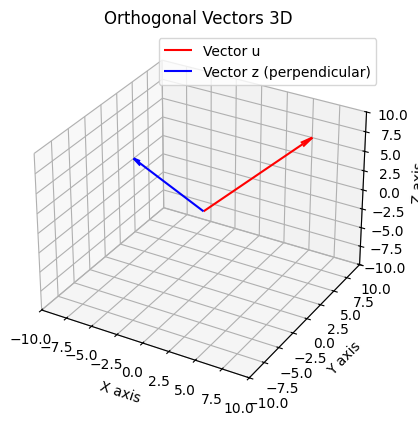

In [72]:
def plot_two_vectors_3d(v1, v2, label1='v1', label2='v2'):
    fig=plt.figure()
    ax=fig.add_subplot(111, projection='3d')
    ax.quiver(0, 0, 0, v1[0], v1[1], v1[2], color='r', label=label1, arrow_length_ratio=0.1)
    ax.quiver(0, 0, 0, v2[0], v2[1], v2[2], color='b', label=label2, arrow_length_ratio=0.1)
    limit=max(max(abs(x) for x in v1), max(abs(x) for x in v2))
    ax.set_xlim([-limit, limit])
    ax.set_ylim([-limit, limit])
    ax.set_zlim([-limit, limit])
    ax.set_xlabel('X axis')
    ax.set_ylabel('Y axis')
    ax.set_zlabel('Z axis')
    ax.legend()
    plt.title('Orthogonal Vectors 3D')
    plt.show()

z = perpendicular_vector_3d(u)
plot_two_vectors_3d(u, z, label1='Vector u', label2='Vector z (perpendicular)')

### Part 3:

**Cauchy–Schwarz Inequality**



$$|\mathbf{u} \cdot \mathbf{v}| \le \|\mathbf{u}\| \cdot \|\mathbf{v}\|$$


(a) For your personalized vectors $\mathbf{u}$ and $\mathbf{v}$, compute:
- $|\mathbf{u} \cdot \mathbf{v}|$
- $\|\mathbf{u}\| \cdot \|\mathbf{v}\|$
and verify numerically that the inequality holds.

(b) complete a Python function `verify_cauchy_schwarz_with_plot(n, N=3000)` that:
- Generates $N$ random pairs of $n$-dimensional vectors (components in $[-1, 1]$).
- For each pair, computes the ratio $r = \frac{|\mathbf{a} \cdot \mathbf{b}|}{\|\mathbf{a}\| \cdot \|\mathbf{b}\|}$ (skip if either norm is near zero).
- Plots a histogram of all computed r .
- Returns the **maximum** ratio observed and the number of pairs with $r > 0.99$..

Run your function for $n = 2$ and $n = 5$ and $n = 10$ report the results.

(c) 
- Explain why the maximum ratio never exceeds 1 (allowing for floating-point rounding). 

- Explain how the histogram changes as $n$ increases. Why are ``nearly parallel'' vectors $(r > 0.99)$ common in 2D but rare in 10D?

---


In [73]:
def personalized_vectors(x, y, z):
    u=[x+2,y+2,z+2]
    v=[y+1,z+1,x+1]
    return u, v
def dot_product(u, v):
    result=0
    for i in range(len(u)):
        result+=u[i]*v[i]
    return result
def euclidean_norm(v):
    result=dot_product(v, v)**0.5
    return result
x, y, z = 3, 8,3
u, v = personalized_vectors(x, y, z)
abs_dot=abs(dot_product(u, v))
norm_dot=euclidean_norm(u)*euclidean_norm(v)
print(f"|u · v| = {abs_dot}")
print(f"||u|| * ||v|| = {norm_dot}")
print(f"Inequality holds? {abs_dot<=norm_dot}")

|u · v| = 105
||u|| * ||v|| = 130.1921656629154
Inequality holds? True


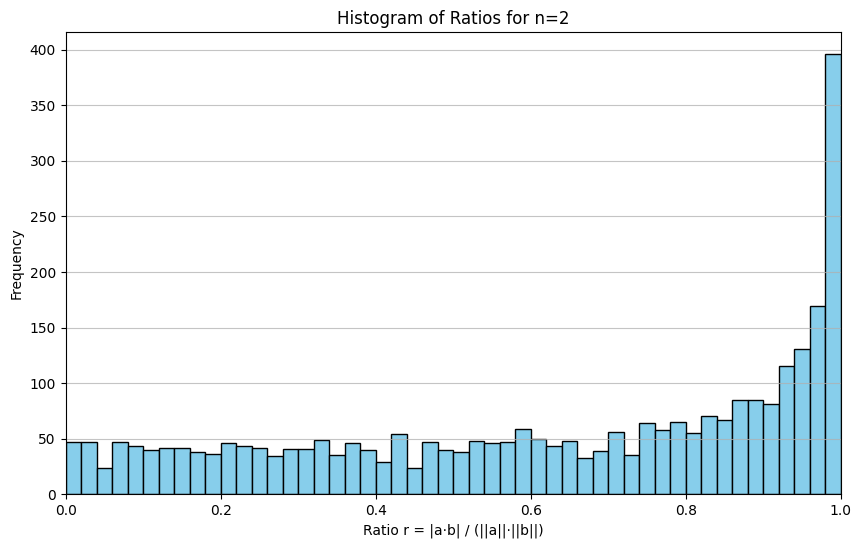

For n = 2:
  Maximum ratio observed: 1.000000
  Number of pairs with r > 0.99: 287
------------------------------


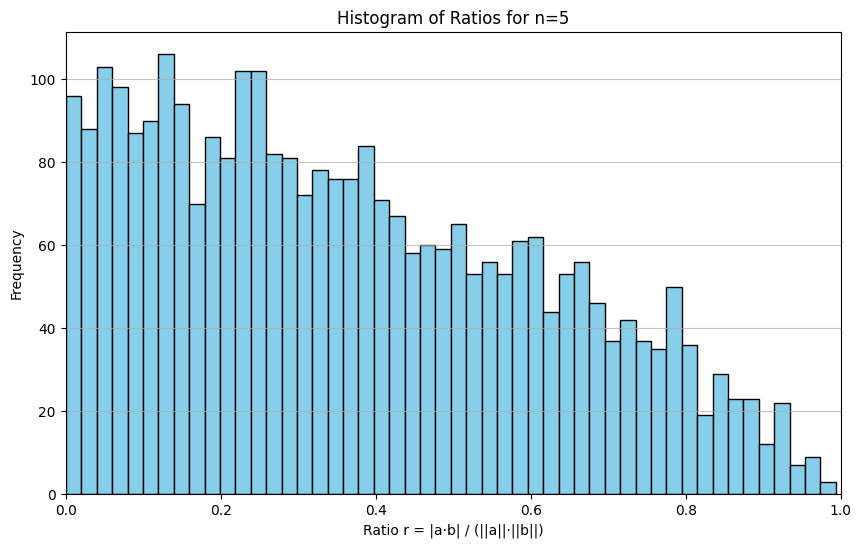

For n = 5:
  Maximum ratio observed: 0.993643
  Number of pairs with r > 0.99: 1
------------------------------


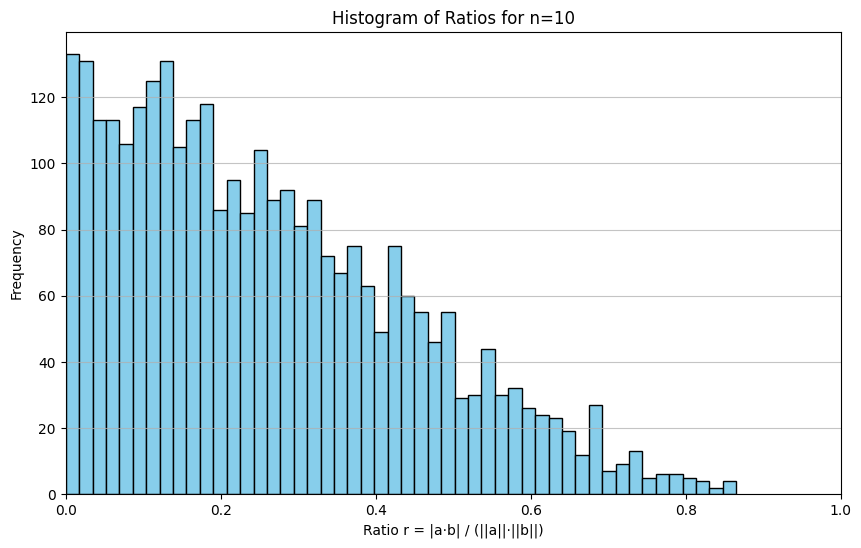

For n = 10:
  Maximum ratio observed: 0.865289
  Number of pairs with r > 0.99: 0
------------------------------


In [75]:
import random
import matplotlib.pyplot as plt

def verify_cauchy_schwarz_with_plot(n, N=3000):
    ratios = []
    count_high = 0
    max_ratio = 0.0
    for i in range(N):
        a = [random.uniform(-1, 1) for _ in range(n)]
        b = [random.uniform(-1, 1) for _ in range(n)]
        if euclidean_norm(u)<1e-8 and euclidean_norm(v)<1e-8:
            continue
        else:
            r=abs(dot_product(a, b))/(euclidean_norm(a)*euclidean_norm(b))
            ratios.append(r)
        if r>max_ratio:
            max_ratio=r
        if r>0.99:
            count_high+=1
    plt.figure(figsize=(10, 6))
    plt.hist(ratios, bins=50, color='skyblue', edgecolor='black')
    plt.title(f'Histogram of Ratios for n={n}')
    plt.xlabel('Ratio r = |a·b| / (||a||·||b||)')
    plt.ylabel('Frequency')
    plt.xlim(0, 1)
    plt.grid(axis='y', alpha=0.75)
    plt.show()
    return max_ratio, count_high

dimensions = [2, 5, 10]
for n in dimensions:
    max_r, count = verify_cauchy_schwarz_with_plot(n)
    print(f"For n = {n}:")
    print(f"  Maximum ratio observed: {max_r:.6f}")
    print(f"  Number of pairs with r > 0.99: {count}")
    print("-" * 30)

 **----------                         Part (c)                     ----------**

In 2D, two vectors only can vary in one plane. but when dimension increases, there is more than just one plane. Thus, the probability of being parallel, decreases.

### Part 4:

**Angle Between Vectors and the Equality Condition**


(a) Write a Python function `angle_between(u, v)` that:
- Computes $\cos \theta = \dfrac{\mathbf{u} \cdot \mathbf{v}}{\|\mathbf{u}\| \cdot \|\mathbf{v}\|}$
- Returns $\theta$ in degrees using `math.acos()`.

The Cauchy–Schwarz inequality guarantees that:

$$-1 \le \frac{\mathbf{u} \cdot \mathbf{v}}{\|\mathbf{u}\| \cdot \|\mathbf{v}\|} \le 1$$

For your personalized vectors $\mathbf{u}$ and $\mathbf{v}$, compute $\theta$ in degrees manually (using $\arccos$) and verify with your Python function `angle_between(u, v)`.

(b) The equality $|\mathbf{a} \cdot \mathbf{b}| = \|\mathbf{a}\| \cdot \|\mathbf{b}\|$ holds if and only if $\mathbf{a}$ and $\mathbf{b}$ are linearly dependent (i.e., one is a scalar multiple of the other).

Prove the "if" direction: If $\mathbf{a} = \mathbf{c} \mathbf{b}$ for some scalar $c$, then $|\mathbf{a} \cdot \mathbf{b}| = \|\mathbf{a}\| \cdot \|\mathbf{b}\|$.

In [60]:
import math
def personalized_vectors(x, y, z):
    u=[x+2,y+2,z+2]
    v=[x+1,y+1,z+1]
    return u, v

def dot_product(u, v):
    result=0
    for i in range(len(u)):
        result+=u[i]*v[i]
    return result
def euclidean_norm(v):
    result=dot_product(v, v)**0.5
    return result
x, y, z = 3, 8,3
u, v = personalized_vectors(x, y, z)

def angle_between(u, v):
    dot_uv=dot_product(u, v)
    cos_theta = dot_uv / (euclidean_norm(u) * euclidean_norm(v))
    if cos_theta>1.0:
        cos_theta = 1.0
    elif cos_theta<-1.0:
        cos_theta = -1.0
    theta=math.acos(cos_theta)
    result = math.degrees(theta)
    return result

theta=angle_between(u,v)
print(f"Angle between u and v is: {theta:.2f} degrees")

Angle between u and v is: 3.11 degrees


In [61]:
def scalar_mult(c, v):
    result=[0 for _ in range(len(v))]
    for i in range(len(v)):
        result[i]=c*v[i]
    return result
c=3
b=[-1,5,9]
a=scalar_mult(c,b)
dot_ab=abs(dot_product(a,b))
norm_dot=euclidean_norm(a)*euclidean_norm(b)
print(f"Vector b = {b}")
print(f"Vector a (c*b) = {a}  where c = {c}")
print(f"|a · b| = {dot_ab}")
print(f"||a|| * ||b|| = {norm_dot}")
print(f"Equality holds? {abs(dot_ab - norm_dot) < 1e-8}")

Vector b = [-1, 5, 9]
Vector a (c*b) = [-3, 15, 27]  where c = 3
|a · b| = 321
||a|| * ||b|| = 321.0
Equality holds? True


### Part 5:  
**Orthogonal Projection**

(a) The orthogonal projection of $\mathbf{u}$ onto $\mathbf{v}$ is:

$$\text{proj}_{\mathbf{v}}(\mathbf{u}) = \frac{\mathbf{u} \cdot \mathbf{v}}{\|\mathbf{v}\|^2} \, \mathbf{v}$$

Write a Python function `projection(u, v)` that computes this projection.

(b) For your personalized vectors $\mathbf{u}$ and $\mathbf{v}$, compute:
- $\mathbf{p} = \text{proj}_{\mathbf{v}}(\mathbf{u})$
- $\mathbf{r} = \mathbf{u} - \mathbf{p}$ (the rejection)

(c) Verify numerically that:
- $\mathbf{p} \cdot \mathbf{r} \approx 0$ (they are perpendicular)
- $\|\mathbf{u}\|^2 \approx \|\mathbf{p}\|^2 + \|\mathbf{r}\|^2$ (Pythagorean theorem)


In [76]:
def personalized_vectors(x, y, z):
    u=[x+2,y+2,z+2]
    v=[y+1,z+1,x+1]
    return u, v

def dot_product(u, v):
    result=0
    for i in range(len(u)):
        result+=u[i]*v[i]
    return result
def euclidean_norm(v):
    result=dot_product(v, v)**0.5
    return result

def vector_add(u, v):
    result=[0 for _ in range(len(u))]
    for i in range(len(u)):
        result[i]=u[i]+v[i]
    return result
def scalar_mult(c, v):
    result=[0 for _ in range(len(v))]
    for i in range(len(v)):
        result[i]=c*v[i]
    return result

def projection(u, v):
    if euclidean_norm(v)<1e-8:
        return [0]*len(v)
    proj_v=scalar_mult(dot_product(u, v)/euclidean_norm(v)**2,v)
    return proj_v

In [77]:
def is_perpendicular(u, v, tol=1e-8):
    result=abs(dot_product(u,v))<tol
    return result

p=projection(u, v)
p2=scalar_mult(-1,p)
r=vector_add(u,p2)
print(f"r = {r}")
print(f"p = {p}")
# ==================== Part (c) ====================
print('-' *30)
result = is_perpendicular(p, r)
print(f"Is p ⟂ r? {result}")
norm_u_sq = dot_product(u, u)
print(f"||u||² = {norm_u_sq}")
norm_r_sq = dot_product(r, r)
norm_p_sq = dot_product(p, p)
print(f"||p||² + ||r||² = {norm_p_sq + norm_r_sq}")
is_pythagorean_valid = abs(norm_u_sq - (norm_p_sq + norm_r_sq)) < 1e-8
print(f"Pythagorean theorem holds? {is_pythagorean_valid}")

r = [-3.3628318584070787, 6.283185840707965, 1.283185840707965]
p = [8.362831858407079, 3.716814159292035, 3.716814159292035]
------------------------------
Is p ⟂ r? True
||u||² = 150
||p||² + ||r||² = 150.0
Pythagorean theorem holds? True
